In [76]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
import tensorflow as tf

In [77]:
def load_data():
    (x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()

    return x_train_full, y_train_full, x_test, y_test

In [78]:
x_train_full, y_train_full, x_test, y_test = load_data()

In [79]:
print(type(x_train_full))

<class 'numpy.ndarray'>


In [80]:
print(f"x_tarin: {x_train_full.shape}, y_train: {y_train_full.shape}")
print(f"x_test: {x_test.shape}, y_test: {y_test.shape}")

x_tarin: (60000, 28, 28), y_train: (60000,)
x_test: (10000, 28, 28), y_test: (10000,)


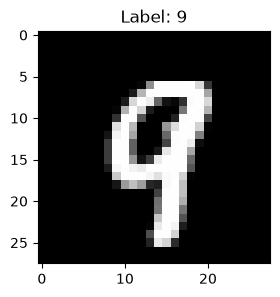

In [81]:
def show_img(show_n = 800):
    plt.figure(figsize=(3, 4))
    plt.imshow(x_train_full[show_n], cmap='gray')
    plt.title(f"Label: {y_train_full[show_n]}")
    plt.show()
show_img()

In [82]:
"""Normalize everything first (using your float32 logic)"""

def scale_data(x_train_full, x_test):
    MAX_INTENSITY = 255.0
    x_train_full_norm = x_train_full.astype("float32") / MAX_INTENSITY
    x_test_norm = x_test.astype("float32") / MAX_INTENSITY
    
    return x_train_full_norm, x_test_norm

In [83]:
x_train_full_norm, x_test_norm = scale_data(x_train_full, x_test)

In [84]:
print(x_train_full_norm.min())
print(x_train_full_norm.max())

print(x_test_norm.min())
print(x_test_norm.max())

0.0
1.0
0.0
1.0


In [85]:
"""Split the already-normalized training data into Train and Val"""

from sklearn.model_selection import train_test_split

def split_data():
    x_train_norm, x_val_norm, y_train, y_val = train_test_split(
        x_train_full_norm, y_train_full, test_size=0.2, random_state=42 
    )
    return x_train_norm, x_val_norm, y_train, y_val

In [86]:
x_train_norm, x_val_norm, y_train, y_val = split_data()

In [87]:
# Verify the final shapes
print("X Train shape:", x_train_norm.shape) 
print("X Val shape:", x_val_norm.shape)     
print("X Test shape:", x_test_norm.shape)

print("Y Train shape:", y_train.shape) 
print("Y Val shape:", y_val.shape)     
print("Y Test shape:", y_test.shape)

X Train shape: (48000, 28, 28)
X Val shape: (12000, 28, 28)
X Test shape: (10000, 28, 28)
Y Train shape: (48000,)
Y Val shape: (12000,)
Y Test shape: (10000,)


In [88]:
len(np.unique(y_train))

10

In [89]:
np.unique(y_train)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

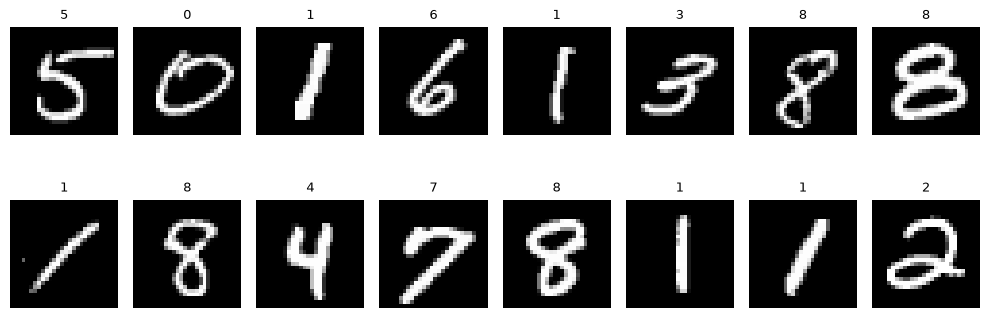

In [90]:
def show_imgs():
    fig, axes = plt.subplots(2, 8, figsize= (10,4))
    for ax, img, label in zip(axes.flat, x_train_norm, y_train):
        ax.imshow(img, cmap="gray")
        ax.set_title(label, fontsize= 9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
show_imgs()

## Reduce LR on plateau

In [91]:
def make_model():    
    model = keras.Sequential([
        keras.layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])
    return model
model = make_model()

In [92]:
def compile_model():
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model
model = compile_model()

In [93]:
def history_model():
    history = model.fit(x_train_norm, y_train, validation_data=(x_val_norm, y_val),
                        epochs=30, batch_size=64, verbose=0)
    return history
history = history_model()

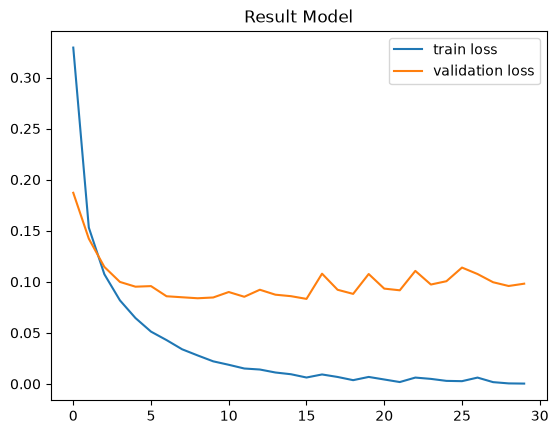

In [94]:
def result_plot():    
    plt.plot(history.history["loss"], label="train loss")
    plt.plot(history.history["val_loss"], label="validation loss")
    plt.title("Result Model")
    plt.legend()
    plt.show()
result_plot()

In [95]:

def train_model_reduce_lr(activation, units, monitor="val_loss", factor=0.8,
                          patience=3, epochs=50, batch_size= 100, verbose=0):
    reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor=monitor, factor=factor, patience=patience)

    train_model = keras.Sequential()
    train_model.add(keras.layers.Input(shape=(28, 28)))
    train_model.add(layers.Flatten())
    for u in units :
        train_model.add(layers.Dense(u, activation=activation))
    train_model.add(layers.Dense(10, activation="softmax"))

    train_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return train_model.fit(x_train_norm, y_train, validation_data=(x_val_norm, y_val), 
                           epochs=epochs, batch_size= batch_size, verbose=verbose, callbacks=[reduce_lr])

In [96]:
histories = {}
for activat in ["relu", "sigmoid", "tanh", "leaky_relu", "swish"]:
    histories[activat] = train_model_reduce_lr(activat, [128, 256, 128, 64, 64, 32, 32])

In [97]:
# history_relu = train_model_reduce_lr("relu", [128, 256, 128, 64, 64, 32, 32])
# history_sigmoid = train_model_reduce_lr("sigmoid", [128, 256, 128, 64, 64, 32, 32])
# history_tanh = train_model_reduce_lr("tanh", [128, 256, 128, 64, 64, 32, 32])
# history_leaky_relu = train_model_reduce_lr("leaky_relu", [128, 256, 128, 64, 64, 32, 32])
# history_swish = train_model_reduce_lr("swish", [128, 256, 128, 64, 64, 32, 32])

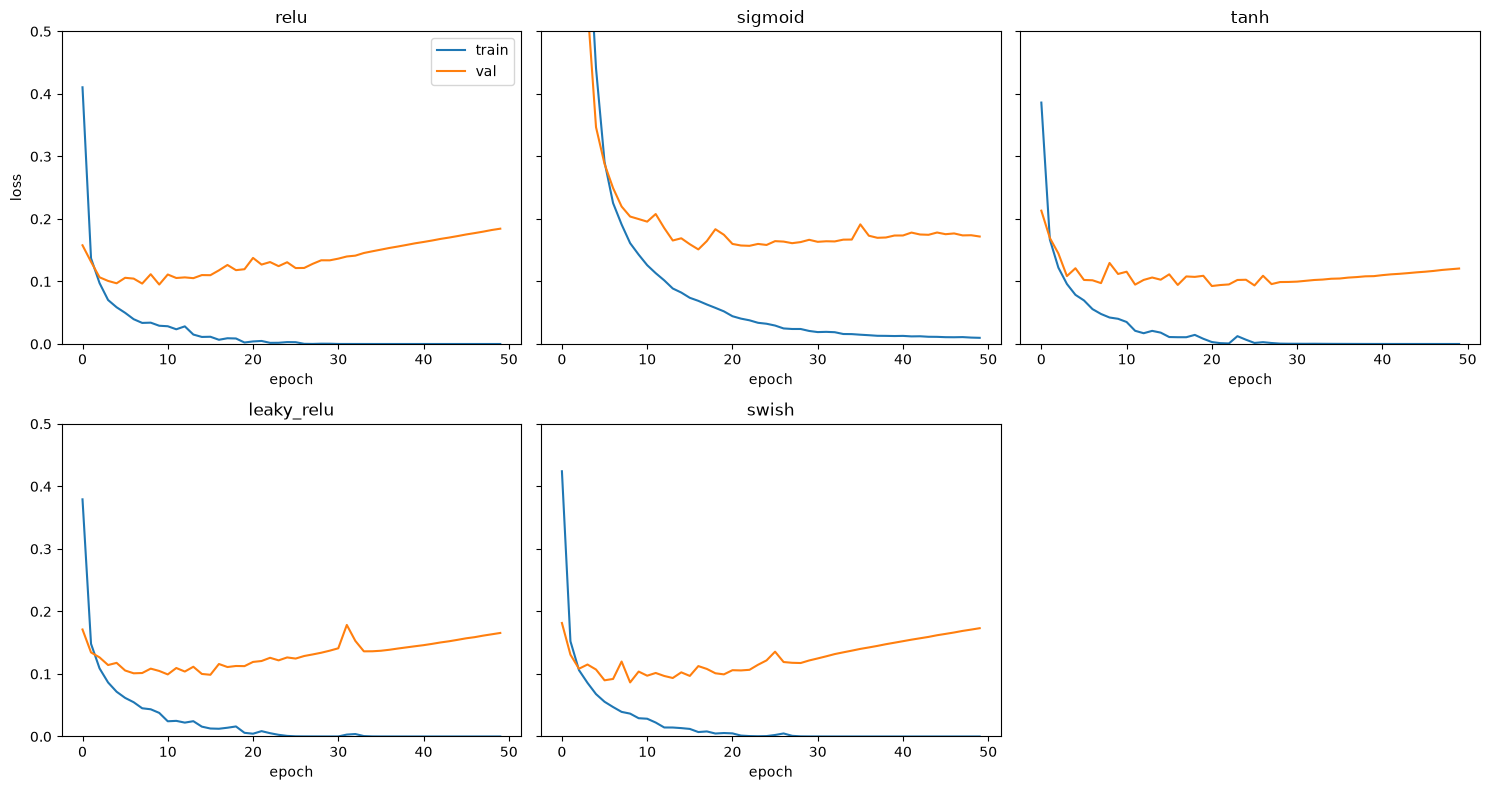

In [101]:
def result_plot(histories):
    fig, axs = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
    axs = axs.flatten()
    for ax, (act, h) in zip(axs, histories.items()):
        ax.plot(h.history["loss"], label= "train")
        ax.plot(h.history["val_loss"], label= "val")
        ax.set_title(act)
        ax.set_xlabel("epoch")
        ax.set_ylim(0, 0.5)
    axs[0].set_ylabel("loss")
    axs[0].legend()
    axs[-1].axis("off")
    plt.tight_layout()
    plt.show()

result_plot(histories)

In [102]:
#change epochs and batch size
def train_model_reduce_lr_2(activation, units, monitor="val_loss", factor=0.8,
                          patience=3, epochs=20, batch_size= 50, verbose=0):
    reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor=monitor, factor=factor, patience=patience)

    train_model = keras.Sequential()
    train_model.add(keras.layers.Input(shape=(28, 28)))
    train_model.add(layers.Flatten())
    for u in units :
        train_model.add(layers.Dense(u, activation=activation))
    train_model.add(layers.Dense(10, activation="softmax"))

    train_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return train_model.fit(x_train_norm, y_train, validation_data=(x_val_norm, y_val), 
                           epochs=epochs, batch_size= batch_size, verbose=verbose, callbacks=[reduce_lr])

In [103]:
histories_2 = {}
for activat in ["relu", "sigmoid", "tanh", "leaky_relu", "swish"]:
    histories_2[activat] = train_model_reduce_lr_2(activat, [128, 256, 128, 64, 64, 32, 32])

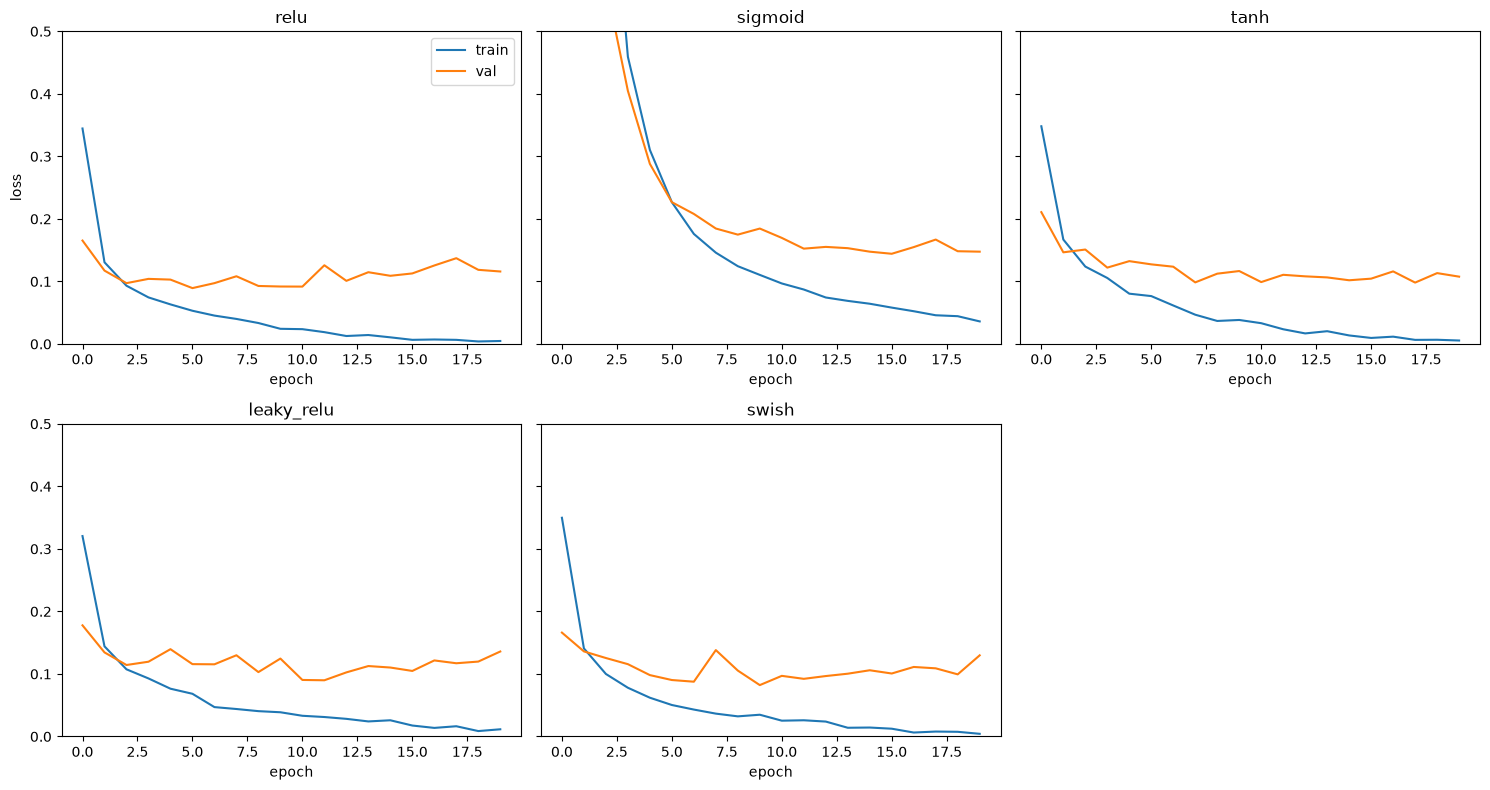

In [104]:
def result_plot_2(histories_2):
    fig, axs = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
    axs = axs.flatten()
    for ax, (act, h) in zip(axs, histories_2.items()):
        ax.plot(h.history["loss"], label= "train")
        ax.plot(h.history["val_loss"], label= "val")
        ax.set_title(act)
        ax.set_xlabel("epoch")
        ax.set_ylim(0, 0.5)
    axs[0].set_ylabel("loss")
    axs[0].legend()
    axs[-1].axis("off")
    plt.tight_layout()
    plt.show()

result_plot_2(histories_2)

In [105]:
# chang n factor and add dropout
def train_model_reduce_lr_3(activation, units, monitor="val_loss", factor=0.5,
                          patience=3, epochs=20, batch_size= 50, verbose=0, dropout=0.2):
    reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor=monitor, factor=factor, patience=patience)

    train_model = keras.Sequential()
    train_model.add(keras.layers.Input(shape=(28, 28)))
    train_model.add(layers.Flatten())
    for u in units :
        train_model.add(layers.Dense(u, activation=activation))
        train_model.add(layers.Dropout(dropout))
    train_model.add(layers.Dense(10, activation="softmax"))

    train_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return train_model.fit(x_train_norm, y_train, validation_data=(x_val_norm, y_val), 
                           epochs=epochs, batch_size= batch_size, verbose=verbose, callbacks=[reduce_lr])

In [106]:
histories_3 = {}
for activat in ["relu", "sigmoid", "tanh", "leaky_relu", "swish"]:
    histories_3[activat] = train_model_reduce_lr_2(activat, [128, 256, 128, 64, 64, 32, 32])

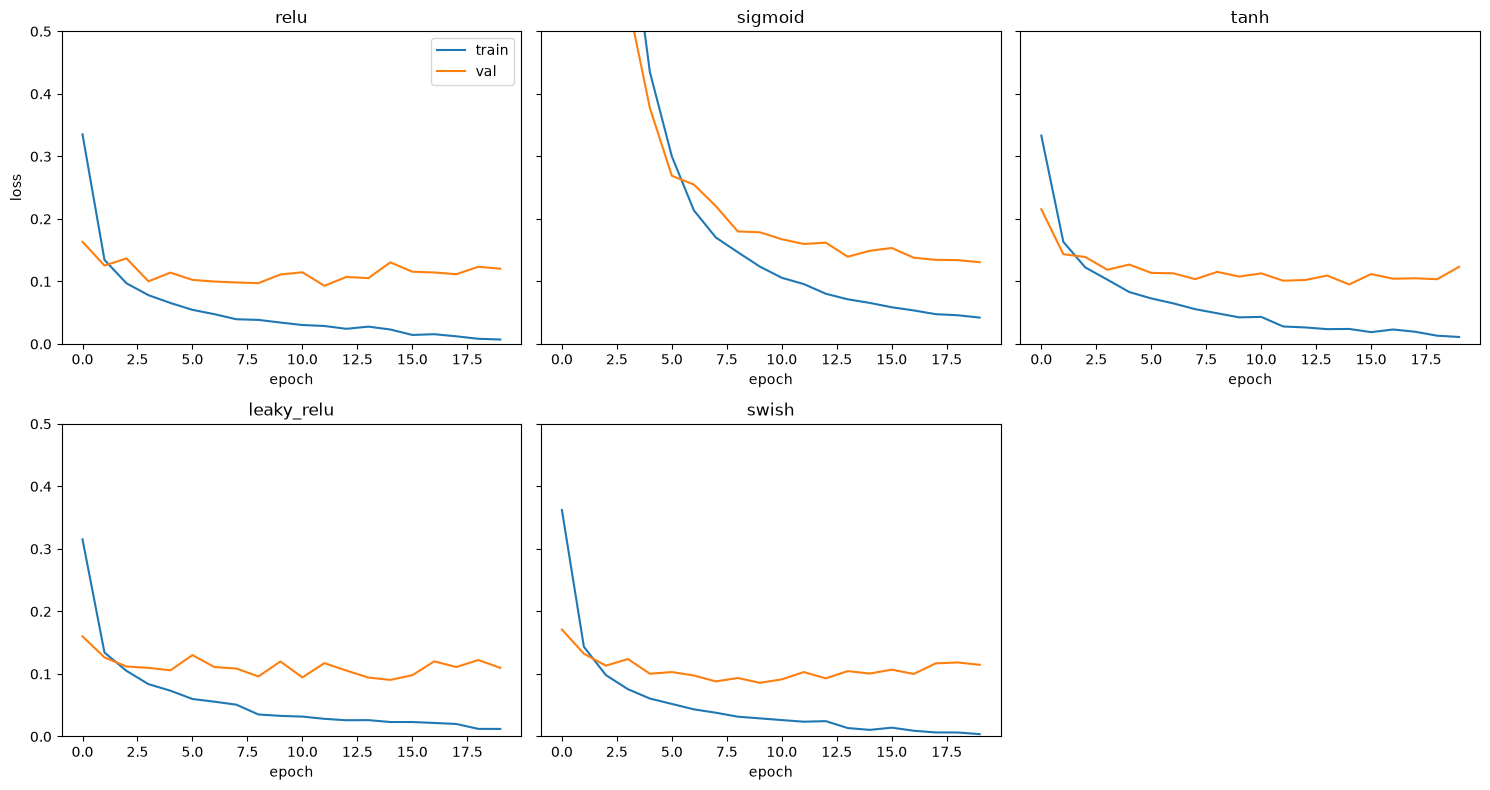

In [107]:
def result_plot_3(histories_3):
    fig, axs = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
    axs = axs.flatten()
    for ax, (act, h) in zip(axs, histories_3.items()):
        ax.plot(h.history["loss"], label= "train")
        ax.plot(h.history["val_loss"], label= "val")
        ax.set_title(act)
        ax.set_xlabel("epoch")
        ax.set_ylim(0, 0.5)
    axs[0].set_ylabel("loss")
    axs[0].legend()
    axs[-1].axis("off")
    plt.tight_layout()
    plt.show()

result_plot_3(histories_3)

In [ ]:
# chang patience
def train_model_reduce_lr_4(activation, units, monitor="val_loss", factor=0.5,
                          patience=1, epochs=20, batch_size= 50, verbose=0, dropout=0.2):
    reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor=monitor, factor=factor, patience=patience)

    train_model = keras.Sequential()
    train_model.add(keras.layers.Input(shape=(28, 28)))
    train_model.add(layers.Flatten())
    for u in units :
        train_model.add(layers.Dense(u, activation=activation))
        train_model.add(layers.Dropout(dropout))
    train_model.add(layers.Dense(10, activation="softmax"))

    train_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return train_model.fit(x_train_norm, y_train, validation_data=(x_val_norm, y_val), 
                           epochs=epochs, batch_size= batch_size, verbose=verbose, callbacks=[reduce_lr])

In [110]:
histories_4 = {}
for activat in ["relu", "sigmoid", "tanh", "leaky_relu", "swish"]:
    histories_4[activat] = train_model_reduce_lr_4(activat, [128, 256, 128, 64, 64, 32, 32])

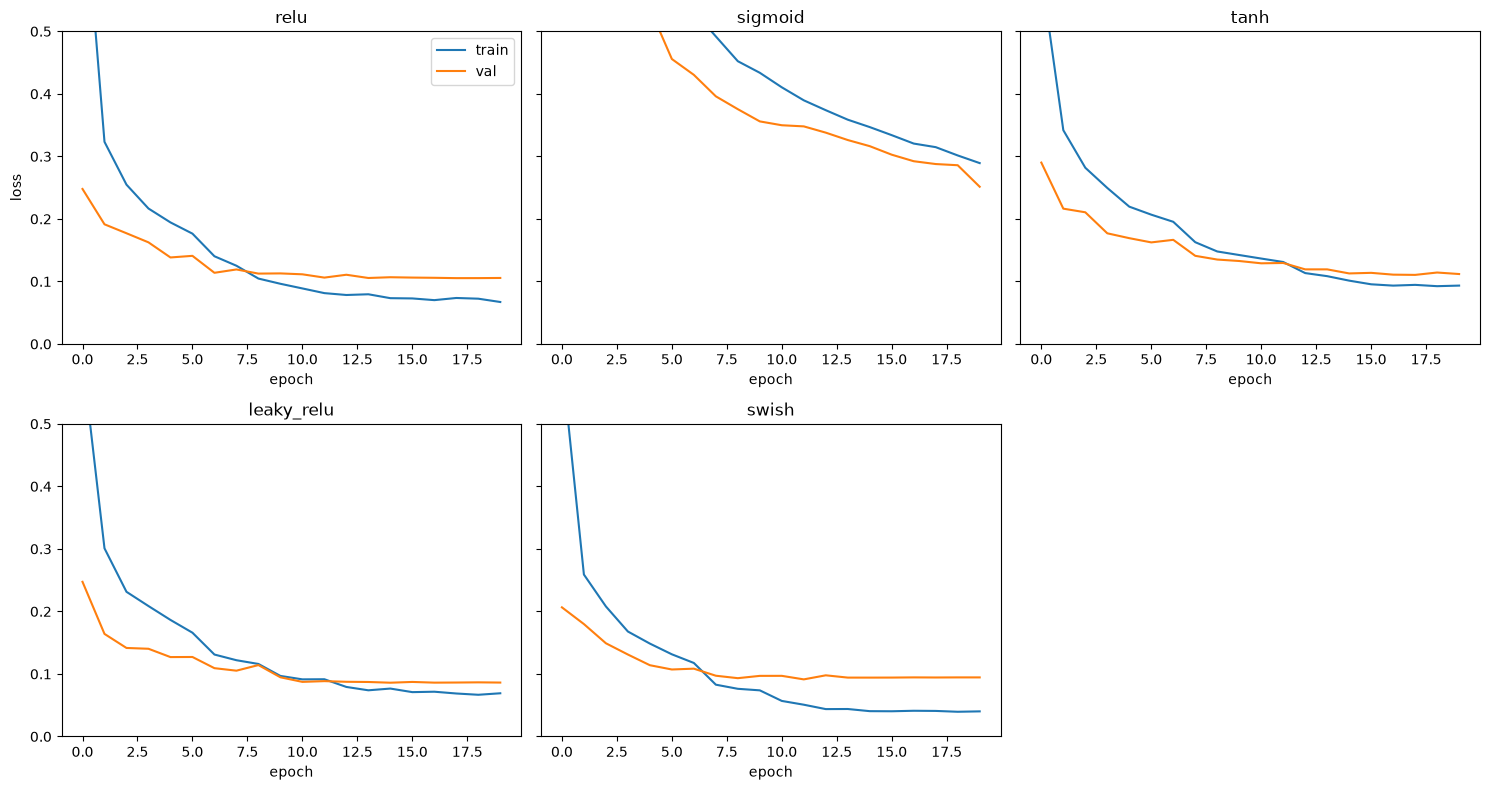

In [111]:
def result_plot_3(histories_4):
    fig, axs = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
    axs = axs.flatten()
    for ax, (act, h) in zip(axs, histories_4.items()):
        ax.plot(h.history["loss"], label= "train")
        ax.plot(h.history["val_loss"], label= "val")
        ax.set_title(act)
        ax.set_xlabel("epoch")
        ax.set_ylim(0, 0.5)
    axs[0].set_ylabel("loss")
    axs[0].legend()
    axs[-1].axis("off")
    plt.tight_layout()
    plt.show()

result_plot_3(histories_4)